In [1]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import datasets, layers, models
from sklearn.metrics import confusion_matrix, classification_report

# Reproductibilité
tf.keras.utils.set_random_seed(42)

# Vérification de l'environnement
print("Version TensorFlow :", tf.__version__)
print("Version NumPy :", np.__version__)
print("GPU disponible :", tf.config.list_physical_devices('GPU'))

print("Bibliothèques importées avec succès !")

Version TensorFlow : 2.21.0
Version NumPy : 2.4.6
GPU disponible : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Bibliothèques importées avec succès !


In [2]:
# ==========================================
# Étape 2 : Chargement du jeu de données
# ==========================================

(X_train, y_train), (X_test, y_test) = datasets.cifar10.load_data()

# Noms des classes
class_names = [
    'Avion', 'Automobile', 'Oiseau', 'Chat',
    'Cerf', 'Chien', 'Grenouille', 'Cheval',
    'Bateau', 'Camion'
]

# Vérification des dimensions
print("Dimensions X_train :", X_train.shape)
print("Dimensions y_train :", y_train.shape)
print("Dimensions X_test  :", X_test.shape)
print("Dimensions y_test  :", y_test.shape)

print("\nNombre de classes :", len(class_names))
print("Type des données :", X_train.dtype)
print("Pixel minimum :", X_train.min())
print("Pixel maximum :", X_train.max())

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Dimensions X_train : (50000, 32, 32, 3)
Dimensions y_train : (50000, 1)
Dimensions X_test  : (10000, 32, 32, 3)
Dimensions y_test  : (10000, 1)

Nombre de classes : 10
Type des données : uint8
Pixel minimum : 0
Pixel maximum : 255


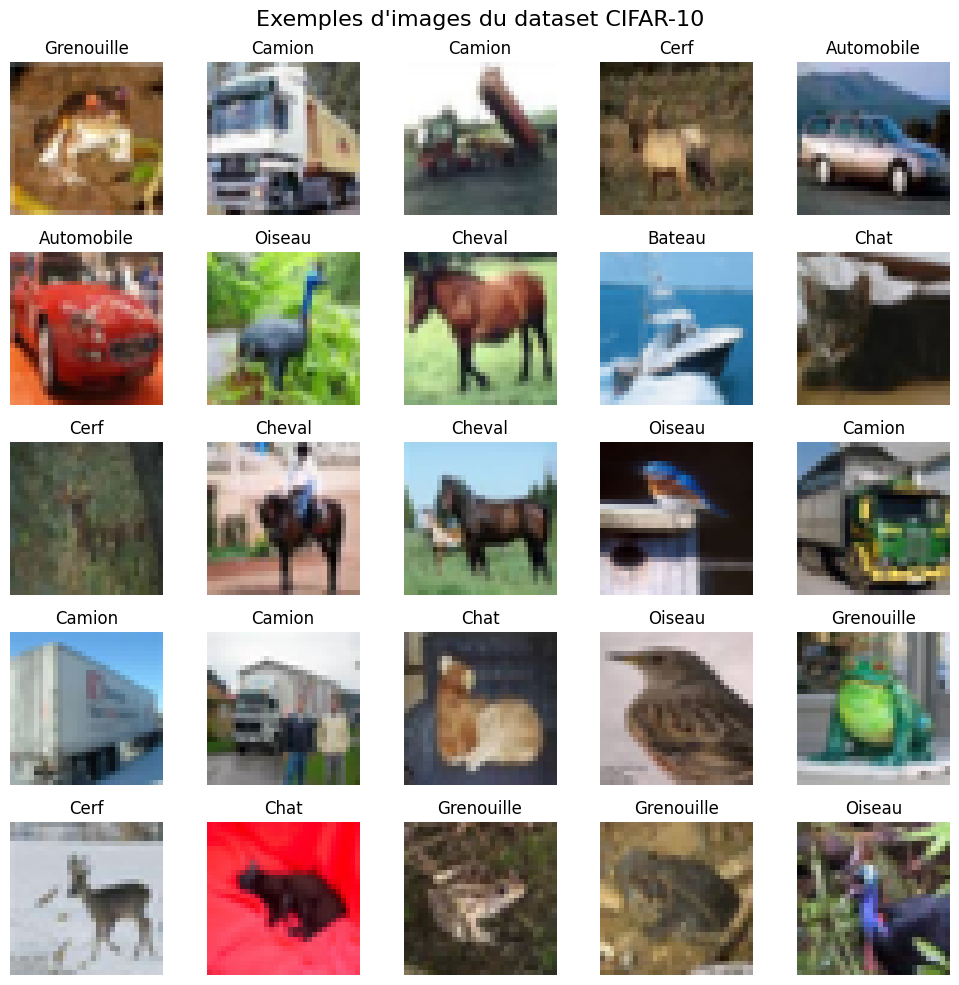

In [3]:
# ==========================================
# Étape 3 : Visualisation des données
# ==========================================

plt.figure(figsize=(10, 10))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X_train[i])
    plt.title(class_names[y_train[i, 0]])
    plt.axis('off')

plt.suptitle("Exemples d'images du dataset CIFAR-10",
             fontsize=16)

plt.tight_layout()
plt.show()

Distribution des classes :

Avion        : Train = 5000 | Test = 1000
Automobile   : Train = 5000 | Test = 1000
Oiseau       : Train = 5000 | Test = 1000
Chat         : Train = 5000 | Test = 1000
Cerf         : Train = 5000 | Test = 1000
Chien        : Train = 5000 | Test = 1000
Grenouille   : Train = 5000 | Test = 1000
Cheval       : Train = 5000 | Test = 1000
Bateau       : Train = 5000 | Test = 1000
Camion       : Train = 5000 | Test = 1000


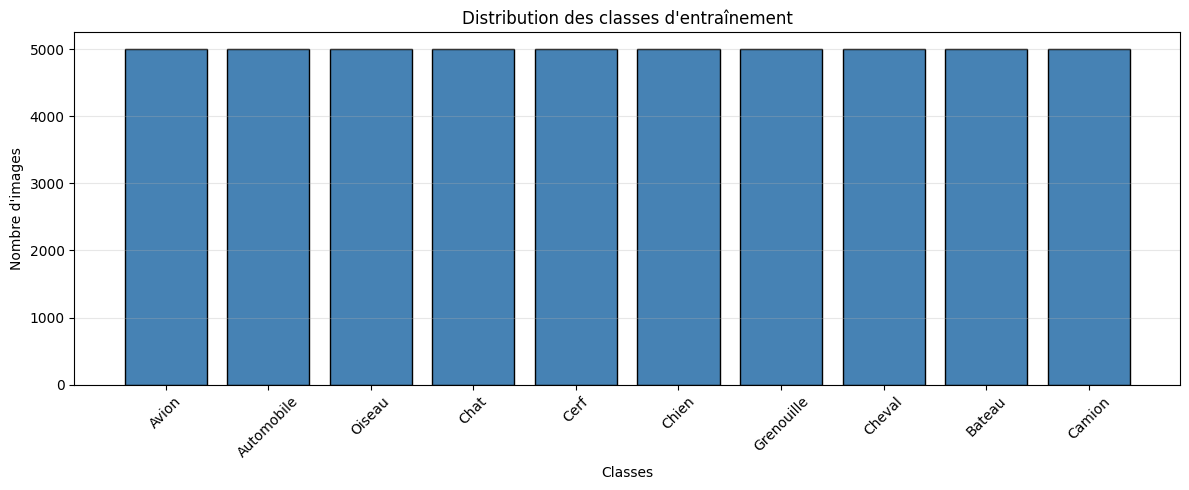

In [4]:
# Distribution des classes

effectifs_train = np.bincount(y_train.flatten())
effectifs_test = np.bincount(y_test.flatten())

print("Distribution des classes :\n")

for i in range(10):
    print(f"{class_names[i]:12s} : "
          f"Train = {effectifs_train[i]} | "
          f"Test = {effectifs_test[i]}")

plt.figure(figsize=(12, 5))

plt.bar(class_names, effectifs_train,
        color='steelblue', edgecolor='black')

plt.title("Distribution des classes d'entraînement")
plt.xlabel("Classes")
plt.ylabel("Nombre d'images")
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
# ==========================================
# Étape 4 : Prétraitement des données
# ==========================================

# Normalisation des pixels
X_train_norm = X_train.astype('float32') / 255.0
X_test_norm = X_test.astype('float32') / 255.0

# Transformation des labels en vecteurs 1D
y_train = y_train.flatten()
y_test = y_test.flatten()

# Vérification
print("Type des données :", X_train_norm.dtype)
print("Pixel minimum :", X_train_norm.min())
print("Pixel maximum :", X_train_norm.max())

print("Dimensions y_train :", y_train.shape)
print("Dimensions y_test :", y_test.shape)

Type des données : float32
Pixel minimum : 0.0
Pixel maximum : 1.0
Dimensions y_train : (50000,)
Dimensions y_test : (10000,)


In [6]:
from sklearn.model_selection import train_test_split

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_norm,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Entraînement :", X_train_final.shape)
print("Validation   :", X_val.shape)
print("Test         :", X_test_norm.shape)

print("\nDistribution des classes :")
print("Train :", np.bincount(y_train_final))
print("Val   :", np.bincount(y_val))
print("Test  :", np.bincount(y_test))

Entraînement : (40000, 32, 32, 3)
Validation   : (10000, 32, 32, 3)
Test         : (10000, 32, 32, 3)

Distribution des classes :
Train : [4000 4000 4000 4000 4000 4000 4000 4000 4000 4000]
Val   : [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]
Test  : [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


In [7]:
# ==========================================
# Étape 5 : Construction du modèle CNN
# ==========================================

model = models.Sequential([

    # Couche d'entrée
    layers.Input(shape=(32, 32, 3)),

    # Premier bloc de convolution
    layers.Conv2D(32, (3, 3), activation='relu',
                  padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Deuxième bloc de convolution
    layers.Conv2D(64, (3, 3), activation='relu',
                  padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Troisième couche de convolution
    layers.Conv2D(64, (3, 3), activation='relu',
                  padding='same'),

    # Transformation en vecteur
    layers.Flatten(),

    # Couche entièrement connectée
    layers.Dense(64, activation='relu'),

    # Couche de sortie : 10 classes
    layers.Dense(10, activation='softmax')

], name="CNN_Baseline")

print("Modèle CNN construit avec succès !")
print("Nombre de paramètres :", model.count_params())

Modèle CNN construit avec succès !
Nombre de paramètres : 319178


In [8]:
# ==========================================
# Étape 6 : Compilation du modèle
# ==========================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Modèle compilé avec succès !")
print("Optimiseur :", model.optimizer.name)
print("Learning rate :", model.optimizer.learning_rate.numpy())
print("Fonction de perte :", model.loss)

Modèle compilé avec succès !
Optimiseur : adam
Learning rate : 0.001
Fonction de perte : sparse_categorical_crossentropy


In [9]:
# ==========================================
# Étape 7 : Synthèse du modèle
# ==========================================

model.summary()

Model: "CNN_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 319,178 (1.22 MB)

 Trainable params: 319,178 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# ==========================================
# Étape 8 : Entraînement du modèle CNN
# ==========================================

import time

start_time = time.time()

history = model.fit(
    X_train_final,
    y_train_final,
    epochs=15,
    batch_size=64,
    validation_data=(X_val, y_val),
    shuffle=True,
    verbose=1
)

training_time = time.time() - start_time

print("\nEntraînement terminé avec succès !")
print(f"Temps d'entraînement : {training_time:.2f} secondes")
print(f"Temps d'entraînement : {training_time/60:.2f} minutes")

Epoch 1/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 14ms/step - accuracy: 0.4570 - loss: 1.4883 - val_accuracy: 0.5969 - val_loss: 1.1576
Epoch 2/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6132 - loss: 1.0931 - val_accuracy: 0.6564 - val_loss: 0.9807
Epoch 3/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.6755 - loss: 0.9218 - val_accuracy: 0.6596 - val_loss: 0.9696
Epoch 4/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7175 - loss: 0.8078 - val_accuracy: 0.6884 - val_loss: 0.9016
Epoch 5/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7446 - loss: 0.7274 - val_accuracy: 0.6931 - val_loss: 0.8829
Epoch 6/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7713 - loss: 0.6532 - val_accuracy: 0.6942 - val_loss: 0.9154
Epoch 7/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7925 - loss: 0.5920 - val_accuracy: 0.6767 - val_loss: 1.0203
Epoch 8/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8150 - loss: 0.5327 - val_accuracy: 

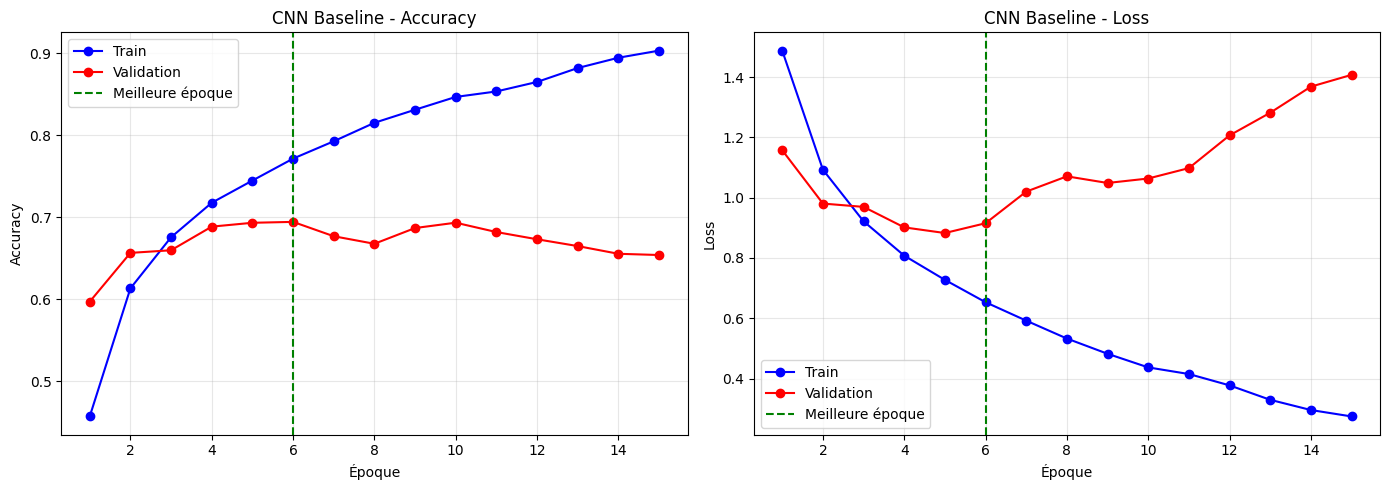

In [11]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(1, len(acc) + 1)
best_epoch = np.argmax(val_acc) + 1

plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, 'b-o', label='Train')
plt.plot(epochs_range, val_acc, 'r-o', label='Validation')

plt.axvline(best_epoch, color='green',
            linestyle='--', label='Meilleure époque')

plt.title("CNN Baseline - Accuracy")
plt.xlabel("Époque")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)

# Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, 'b-o', label='Train')
plt.plot(epochs_range, val_loss, 'r-o', label='Validation')

plt.axvline(best_epoch, color='green',
            linestyle='--', label='Meilleure époque')

plt.title("CNN Baseline - Loss")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("courbes_CNN_baseline.png",
            dpi=300, bbox_inches='tight')
plt.show()

# Sauvegarder le modèle de référence
model.save("CNN_Baseline.keras")

In [12]:
# ==========================================
# CNN amélioré : Dropout + Data Augmentation
# ==========================================

tf.keras.utils.set_random_seed(42)

# Data Augmentation
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomZoom(0.1)
], name="Data_Augmentation")

# Construction du CNN amélioré
model_improved = models.Sequential([

    layers.Input(shape=(32, 32, 3)),

    # Augmentation des données
    data_augmentation,

    # Premier bloc
    layers.Conv2D(32, (3, 3),
                  activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Deuxième bloc
    layers.Conv2D(64, (3, 3),
                  activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Troisième convolution
    layers.Conv2D(64, (3, 3),
                  activation='relu', padding='same'),

    layers.Flatten(),

    # Classification
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.50),

    layers.Dense(10, activation='softmax')

], name="CNN_Improved")

model_improved.summary()

Model: "CNN_Improved"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Data_Augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 319,178 (1.22 MB)

 Trainable params: 319,178 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
import time

# ==========================================
# 1. Compilation du CNN amélioré
# ==========================================

model_improved.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN amélioré compilé avec succès !")

# ==========================================
# 2. Entraînement du CNN amélioré
# ==========================================

start_time_improved = time.time()

history_improved = model_improved.fit(
    X_train_final,
    y_train_final,
    epochs=30,
    batch_size=64,
    validation_data=(X_val, y_val),
    shuffle=True,
    verbose=1
)

training_time_improved = time.time() - start_time_improved

# ==========================================
# 3. Affichage des résultats
# ==========================================

print("\nEntraînement terminé avec succès !")
print(f"Temps : {training_time_improved:.2f} secondes")
print(f"Durée : {training_time_improved/60:.2f} minutes")

# ==========================================
# 4. Sauvegarde du modèle
# ==========================================

model_improved.save("CNN_Improved.keras")

print("Modèle sauvegardé avec succès !")

CNN amélioré compilé avec succès !
Epoch 1/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.3642 - loss: 1.7057 - val_accuracy: 0.5008 - val_loss: 1.4019
Epoch 2/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.4139 - loss: 1.5939 - val_accuracy: 0.5006 - val_loss: 1.4049
Epoch 3/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.4441 - loss: 1.5353 - val_accuracy: 0.5274 - val_loss: 1.3031
Epoch 4/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.4626 - loss: 1.4826 - val_accuracy: 0.5547 - val_loss: 1.2312
Epoch 5/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.4785 - loss: 1.4440 - val_accuracy: 0.5731 - val_loss: 1.1797
Epoch 6/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.4857 - loss: 1.4216 - val_accuracy: 0.5864 - val_loss: 1.1656
Epoch 7/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.4994 - loss: 1.3864 - val_accuracy: 0.5999 - val_loss: 1.1241
Epoch 8/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.

In [15]:
tf.keras.utils.set_random_seed(42)

# Data Augmentation modérée
data_augmentation_v2 = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.02),
    layers.RandomTranslation(0.05, 0.05)
], name="Data_Augmentation_V2")

model_v2 = models.Sequential([

    layers.Input(shape=(32, 32, 3)),

    data_augmentation_v2,

    # Bloc 1
    layers.Conv2D(32, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.Conv2D(32, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.10),

    # Bloc 2
    layers.Conv2D(64, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.Conv2D(64, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.15),

    # Bloc 3
    layers.Conv2D(128, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.Conv2D(128, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.20),

    # Classification
    layers.Flatten(),

    layers.Dense(128),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Dropout(0.30),

    layers.Dense(10, activation='softmax')

], name="CNN_Optimized_V2")

model_v2.summary()

Model: "CNN_Optimized_V2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Data_Augmentation_V2            │ (None, 32, 32, 3)      │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           51

 Total params: 552,874 (2.11 MB)

 Trainable params: 551,722 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [16]:
import time

# Compilation
model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Optimisation automatique du learning rate
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

# Sauvegarde du meilleur modèle
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "CNN_Best_V2.keras",
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

# Entraînement
start_time_v2 = time.time()

history_v2 = model_v2.fit(
    X_train_final,
    y_train_final,
    epochs=30,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[reduce_lr, checkpoint],
    shuffle=True,
    verbose=1
)

training_time_v2 = time.time() - start_time_v2

# Chargement du meilleur modèle
model_v2 = tf.keras.models.load_model(
    "CNN_Best_V2.keras"
)

print("\nEntraînement terminé !")
print(f"Durée : {training_time_v2/60:.2f} minutes")

print(f"Meilleure accuracy validation : "
      f"{max(history_v2.history['val_accuracy'])*100:.2f} %")

print(f"Meilleure époque : "
      f"{np.argmax(history_v2.history['val_accuracy'])+1}")

Epoch 1/30
624/625 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.3709 - loss: 1.7582
Epoch 1: val_accuracy improved from None to 0.49880, saving model to CNN_Best_V2.keras

Epoch 1: finished saving model to CNN_Best_V2.keras
625/625 ━━━━━━━━━━━━━━━━━━━━ 19s 22ms/step - accuracy: 0.4542 - loss: 1.5091 - val_accuracy: 0.4988 - val_loss: 1.5975 - learning_rate: 0.0010
Epoch 2/30
624/625 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5895 - loss: 1.1582
Epoch 2: val_accuracy improved from 0.49880 to 0.62380, saving model to CNN_Best_V2.keras

Epoch 2: finished saving model to CNN_Best_V2.keras
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 20ms/step - accuracy: 0.6119 - loss: 1.0965 - val_accuracy: 0.6238 - val_loss: 1.0834 - learning_rate: 0.0010
Epoch 3/30
624/625 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6648 - loss: 0.9596
Epoch 3: val_accuracy improved from 0.62380 to 0.69690, saving model to CNN_Best_V2.keras

Epoch 3: finished saving model to CNN_Best_V2.keras
625/625 ━━━━━━━━━━━━━━━━━━━

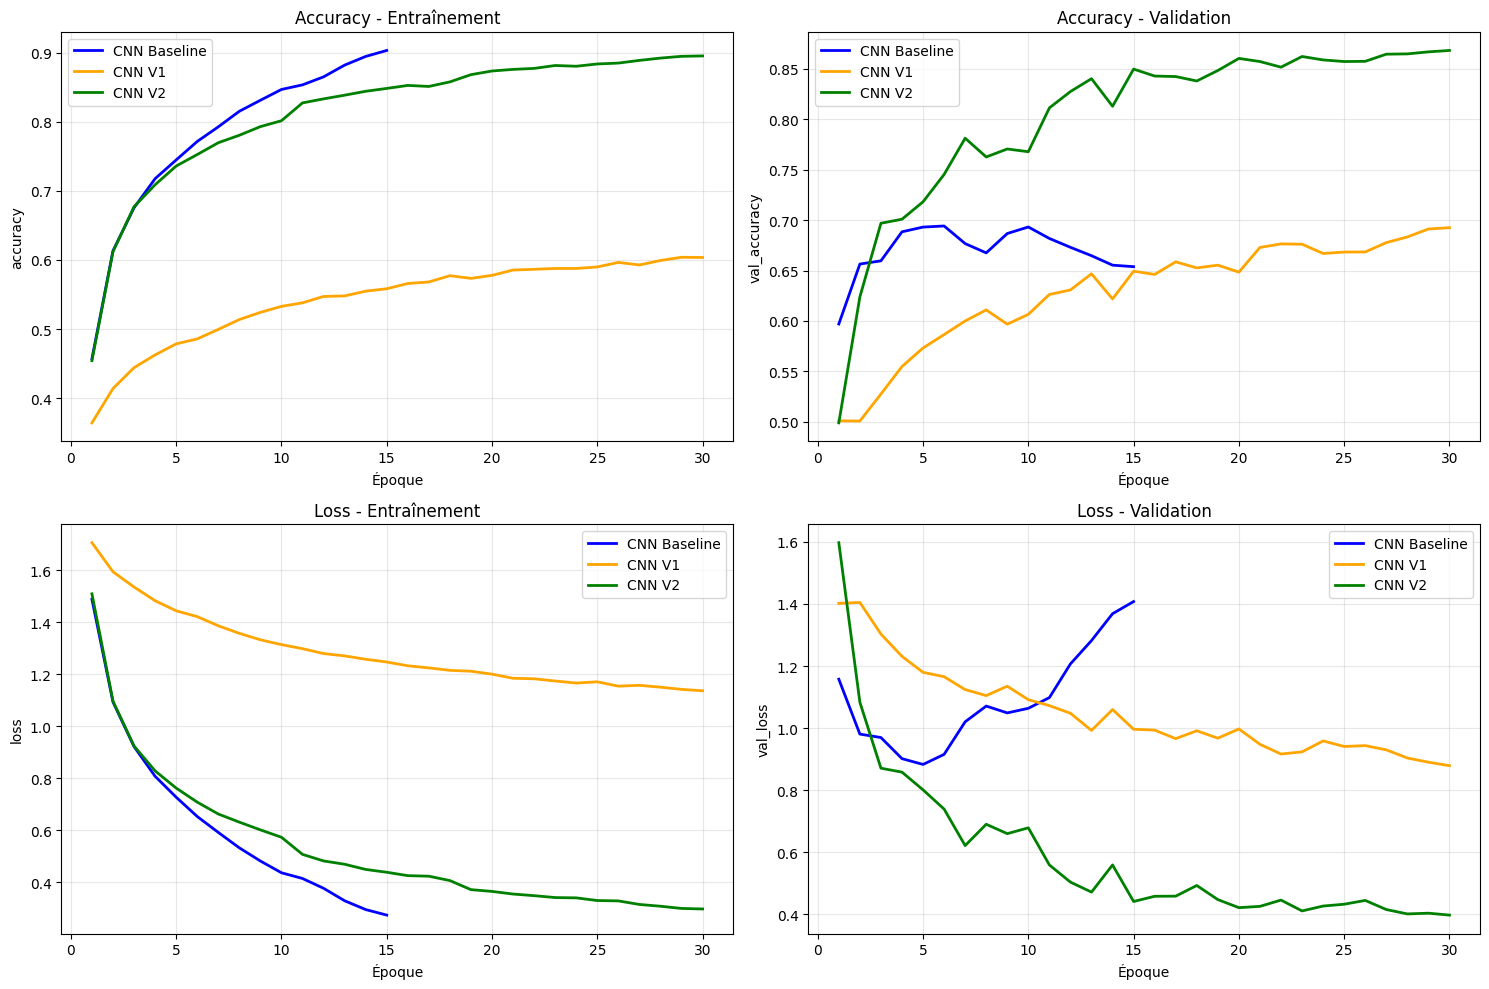

In [17]:
# Comparaison des courbes d'apprentissage

histories = {
    "CNN Baseline": history,
    "CNN V1": history_improved,
    "CNN V2": history_v2
}

colors = {
    "CNN Baseline": "blue",
    "CNN V1": "orange",
    "CNN V2": "green"
}

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

metrics = [
    ("accuracy", "Accuracy - Entraînement"),
    ("val_accuracy", "Accuracy - Validation"),
    ("loss", "Loss - Entraînement"),
    ("val_loss", "Loss - Validation")
]

for ax, (metric, title) in zip(axes.flat, metrics):

    for name, hist in histories.items():

        values = hist.history[metric]
        epochs = range(1, len(values) + 1)

        ax.plot(
            epochs,
            values,
            label=name,
            color=colors[name],
            linewidth=2
        )

    ax.set_title(title)
    ax.set_xlabel("Époque")
    ax.set_ylabel(metric)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "comparaison_3_CNN.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
# ==========================================
# Évaluation finale des trois modèles
# ==========================================

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

cnn_models = {
    "CNN Baseline": model,
    "CNN V1": model_improved,
    "CNN V2": model_v2
}

results = []
predictions = {}

for name, cnn in cnn_models.items():

    # Évaluation sur les données de test
    test_loss, test_acc = cnn.evaluate(
        X_test_norm,
        y_test,
        verbose=0
    )

    # Prédictions
    y_prob = cnn.predict(X_test_norm, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    predictions[name] = y_pred

    # Calcul des métriques
    results.append({
        "Modèle": name,
        "Accuracy (%)": accuracy_score(y_test, y_pred)*100,
        "Precision (%)": precision_score(
            y_test, y_pred, average='macro',
            zero_division=0
        )*100,
        "Recall (%)": recall_score(
            y_test, y_pred, average='macro',
            zero_division=0
        )*100,
        "F1-score (%)": f1_score(
            y_test, y_pred, average='macro',
            zero_division=0
        )*100,
        "Test Loss": test_loss
    })

# Tableau comparatif
df_results = pd.DataFrame(results)

display(df_results.round(4))

# Sauvegarde des résultats
df_results.to_csv("comparaison_CNN.csv", index=False)

,Modèle,Accuracy (%),Precision (%),Recall (%),F1-score (%),Test Loss
0,CNN Baseline,65.63,67.1536,65.63,65.5905,1.4047
1,CNN V1,69.00,69.1609,69.00,68.0390,0.8869
2,CNN V2,86.24,86.2912,86.24,86.1262,0.4287


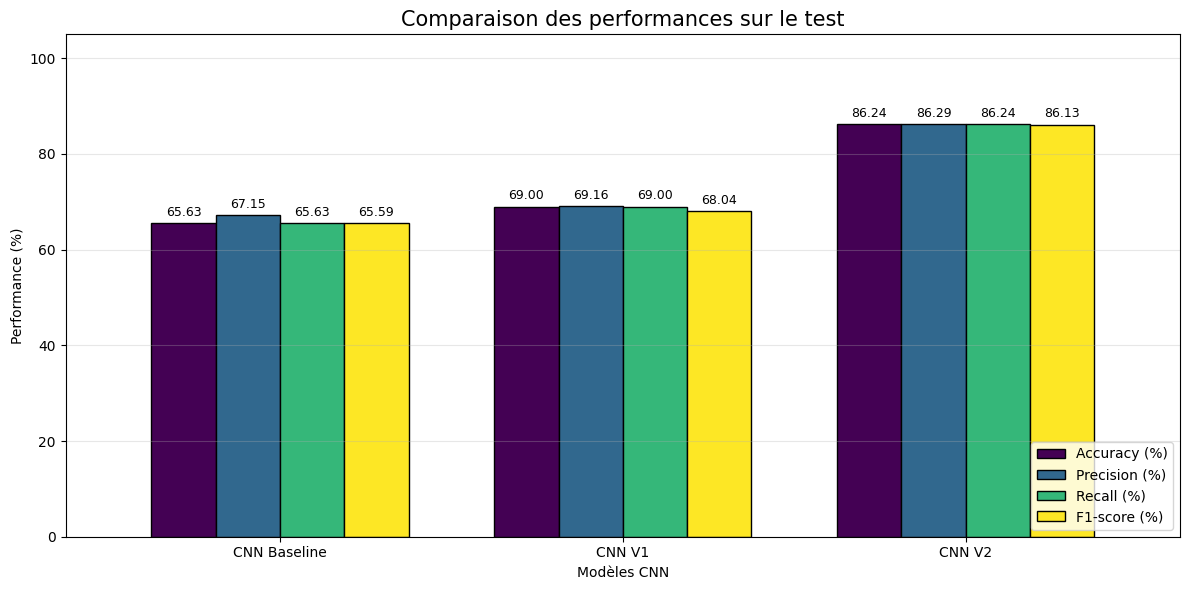

In [19]:
metrics = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-score (%)"
]

ax = df_results.set_index("Modèle")[metrics].plot(
    kind='bar',
    figsize=(12, 6),
    width=0.75,
    colormap='viridis',
    edgecolor='black'
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f',
        fontsize=9,
        padding=3
    )

plt.title("Comparaison des performances sur le test",
          fontsize=15)

plt.ylabel("Performance (%)")
plt.xlabel("Modèles CNN")
plt.ylim(0, 105)
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.legend(loc='lower right')
plt.tight_layout()

plt.savefig("comparaison_test_CNN.png",
            dpi=300, bbox_inches='tight')

plt.show()

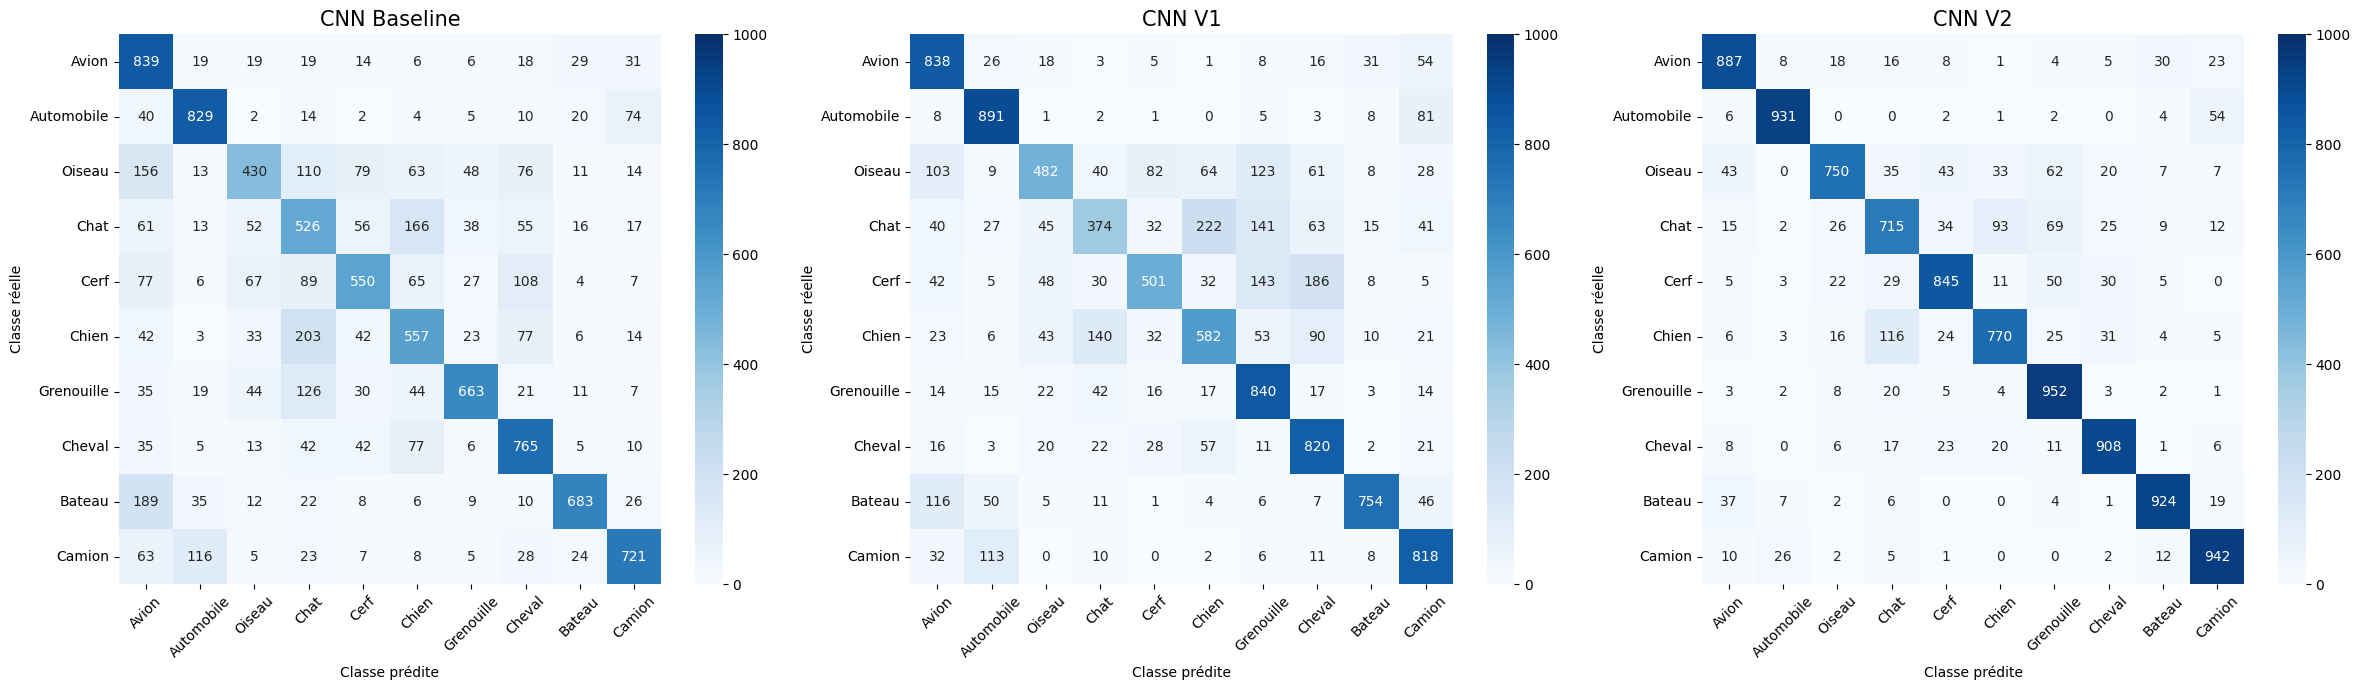

In [20]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

for ax, (name, y_pred) in zip(axes, predictions.items()):

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        vmin=0,
        vmax=1000,
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(name, fontsize=15)
    ax.set_xlabel("Classe prédite")
    ax.set_ylabel("Classe réelle")
    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)

plt.tight_layout()

plt.savefig(
    "matrices_confusion_CNN.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [21]:
from sklearn.metrics import classification_report

for name, y_pred in predictions.items():

    print("=" * 70)
    print("Rapport de classification :", name)
    print("=" * 70)

    print(classification_report(
        y_test,
        y_pred,
        target_names=class_names,
        digits=4,
        zero_division=0
    ))

Rapport de classification : CNN Baseline
              precision    recall  f1-score   support

       Avion     0.5459    0.8390    0.6614      1000
  Automobile     0.7836    0.8290    0.8056      1000
      Oiseau     0.6352    0.4300    0.5128      1000
        Chat     0.4480    0.5260    0.4839      1000
        Cerf     0.6627    0.5500    0.6011      1000
       Chien     0.5592    0.5570    0.5581      1000
  Grenouille     0.7988    0.6630    0.7246      1000
      Cheval     0.6550    0.7650    0.7057      1000
      Bateau     0.8443    0.6830    0.7551      1000
      Camion     0.7828    0.7210    0.7507      1000

    accuracy                         0.6563     10000
   macro avg     0.6715    0.6563    0.6559     10000
weighted avg     0.6715    0.6563    0.6559     10000

Rapport de classification : CNN V1
              precision    recall  f1-score   support

       Avion     0.6802    0.8380    0.7509      1000
  Automobile     0.7782    0.8910    0.8308      1000
  

,CNN Baseline,CNN V1,CNN V2
Avion,83.9,83.8,88.7
Automobile,82.9,89.1,93.1
Oiseau,43.0,48.2,75.0
Chat,52.6,37.4,71.5
Cerf,55.0,50.1,84.5
Chien,55.7,58.2,77.0
Grenouille,66.3,84.0,95.2
Cheval,76.5,82.0,90.8
Bateau,68.3,75.4,92.4
Camion,72.1,81.8,94.2


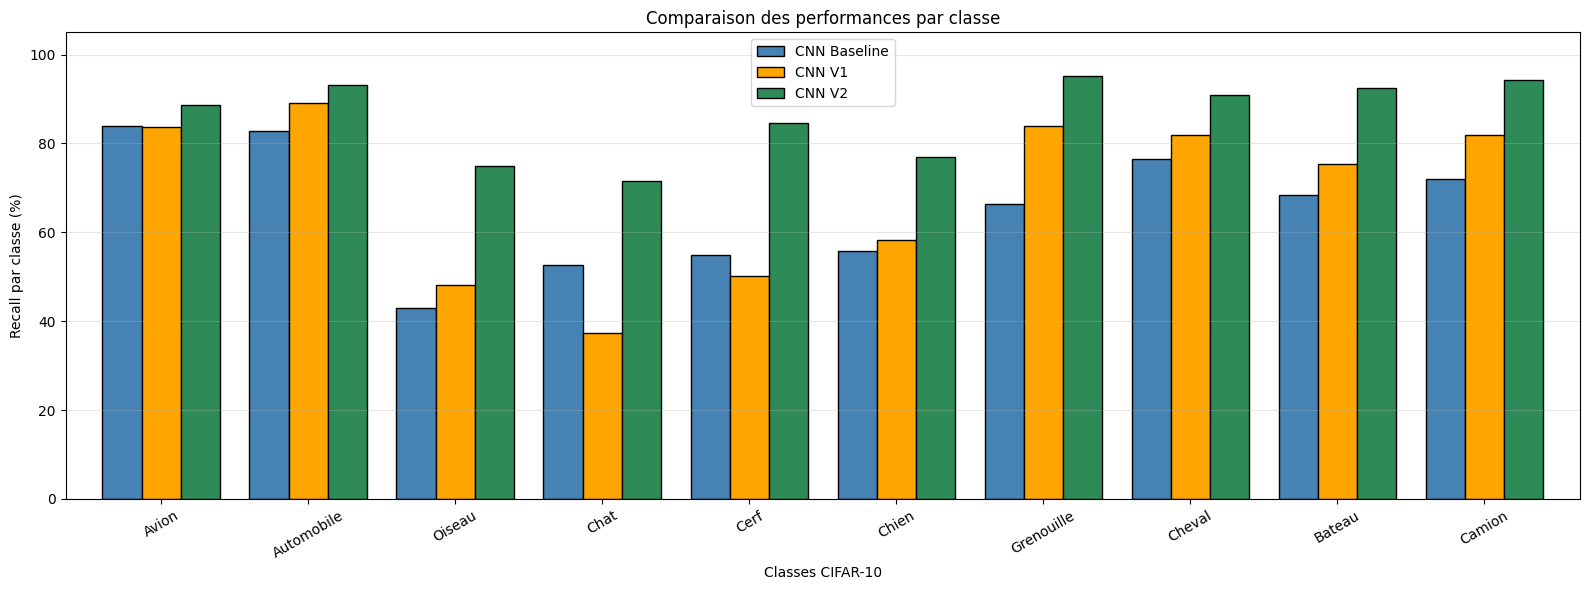

In [22]:
class_results = {}

for name, y_pred in predictions.items():

    cm = confusion_matrix(y_test, y_pred)

    class_accuracy = (
        cm.diagonal() / cm.sum(axis=1)
    ) * 100

    class_results[name] = class_accuracy

df_classes = pd.DataFrame(
    class_results,
    index=class_names
)

display(df_classes.round(2))

ax = df_classes.plot(
    kind='bar',
    figsize=(16, 6),
    color=['steelblue', 'orange', 'seagreen'],
    edgecolor='black',
    width=0.8
)

plt.title("Comparaison des performances par classe")
plt.xlabel("Classes CIFAR-10")
plt.ylabel("Recall par classe (%)")
plt.ylim(0, 105)
plt.xticks(rotation=30)
plt.grid(axis='y', alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "comparaison_par_classe.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

Nombre total d'images : 10000
Images correctement classifiées : 8624
Images mal classifiées : 1376
Taux d'erreur : 13.76 %


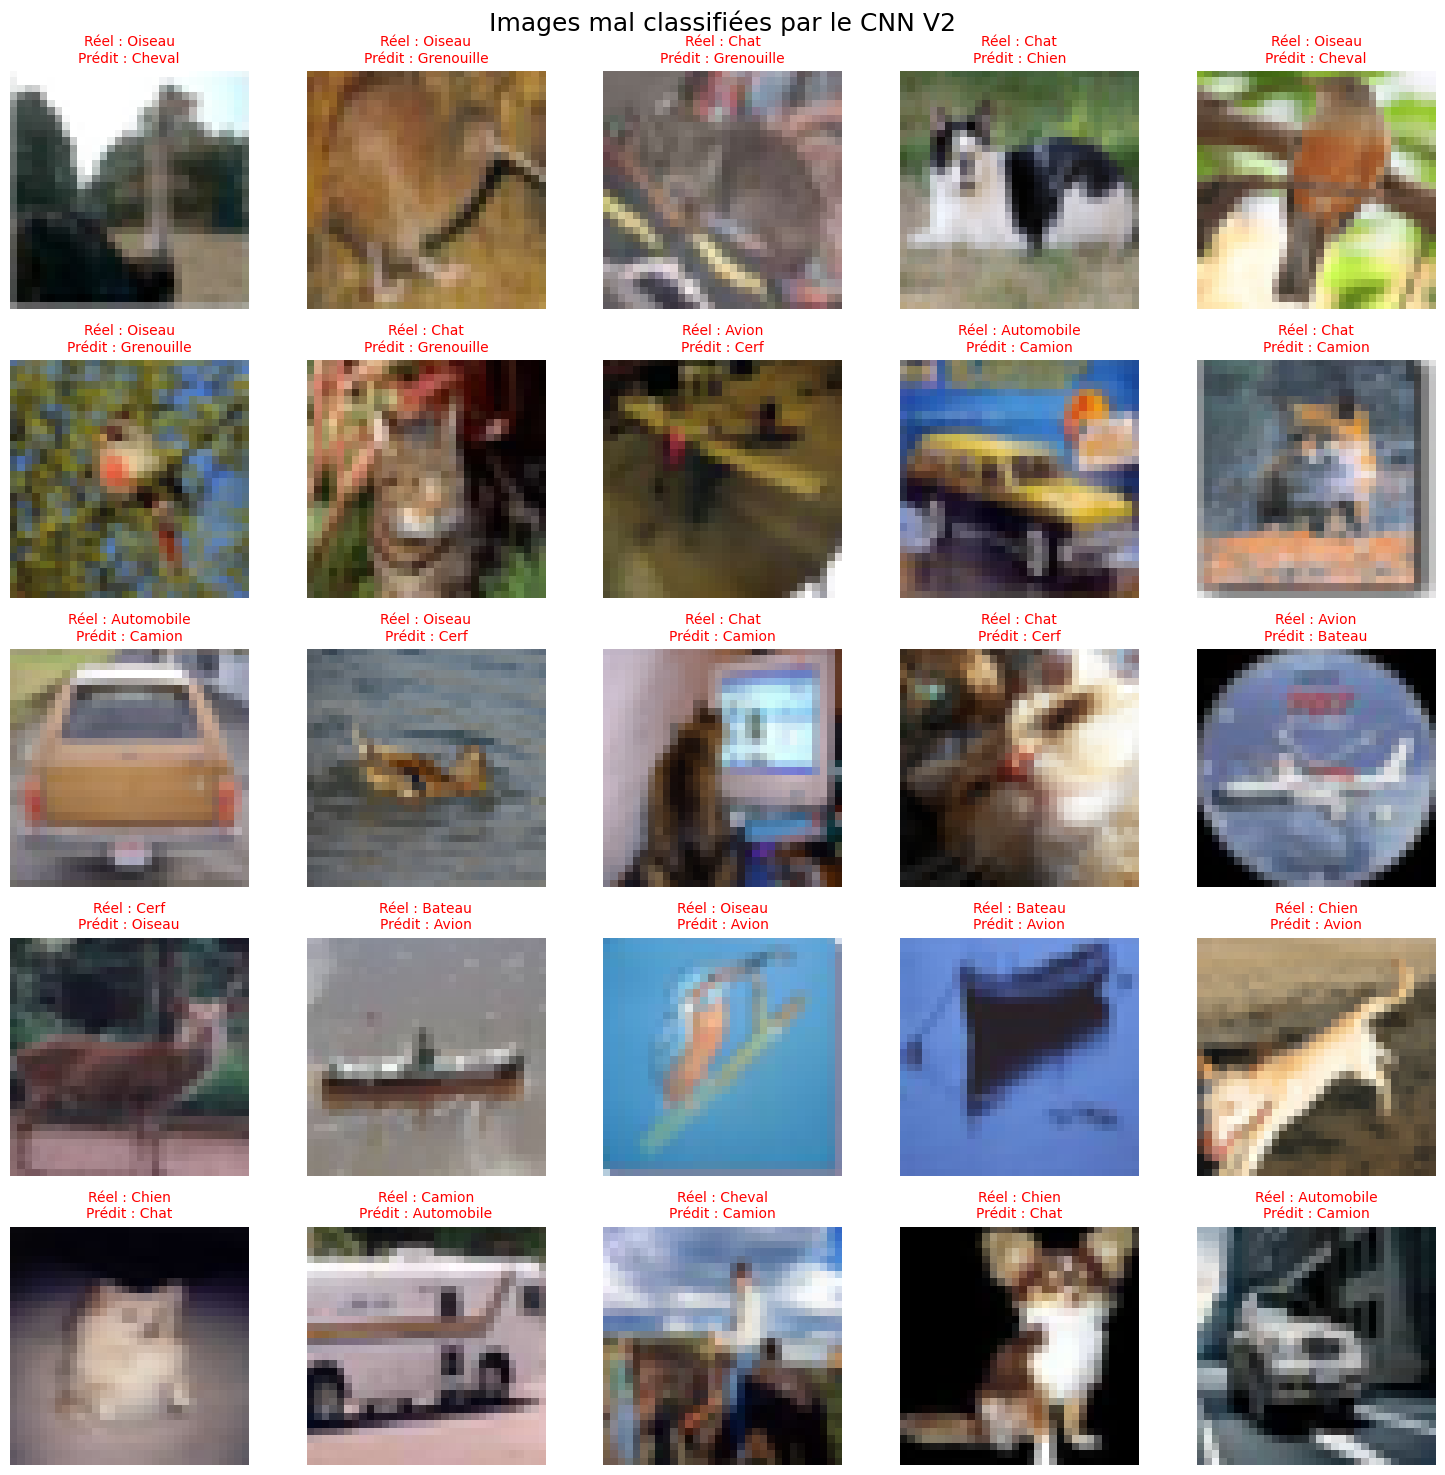

In [23]:
# Récupération des prédictions du CNN V2
y_pred_v2 = predictions["CNN V2"]

# Identification des erreurs
wrong_indices = np.where(y_pred_v2 != y_test)[0]

print("Nombre total d'images :", len(y_test))
print("Images correctement classifiées :",
      len(y_test) - len(wrong_indices))
print("Images mal classifiées :", len(wrong_indices))

print(f"Taux d'erreur : "
      f"{len(wrong_indices)/len(y_test)*100:.2f} %")

# Sélection aléatoire de 25 erreurs
rng = np.random.default_rng(42)

selected_indices = rng.choice(
    wrong_indices,
    size=min(25, len(wrong_indices)),
    replace=False
)

plt.figure(figsize=(15, 15))

for i, idx in enumerate(selected_indices):

    plt.subplot(5, 5, i + 1)
    plt.imshow(X_test[idx])

    true_class = class_names[y_test[idx]]
    pred_class = class_names[y_pred_v2[idx]]

    plt.title(
        f"Réel : {true_class}\nPrédit : {pred_class}",
        color="red",
        fontsize=10
    )

    plt.axis("off")

plt.suptitle(
    "Images mal classifiées par le CNN V2",
    fontsize=18
)

plt.tight_layout()

plt.savefig(
    "erreurs_classification_V2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
cm_v2 = confusion_matrix(y_test, y_pred_v2)

# Supprimer les prédictions correctes
cm_errors = cm_v2.copy()
np.fill_diagonal(cm_errors, 0)

errors = []

for i in range(10):
    for j in range(10):

        if i != j:

            errors.append({
                "Classe réelle": class_names[i],
                "Classe prédite": class_names[j],
                "Nombre d'erreurs": cm_errors[i, j]
            })

df_errors = pd.DataFrame(errors)

df_errors = df_errors.sort_values(
    "Nombre d'erreurs",
    ascending=False
).reset_index(drop=True)

print("Top 10 des confusions les plus fréquentes :")

display(df_errors.head(10))

Top 10 des confusions les plus fréquentes :


,Classe réelle,Classe prédite,Nombre d'erreurs
0,Chien,Chat,116
1,Chat,Chien,93
2,Chat,Grenouille,69
3,Oiseau,Grenouille,62
4,Automobile,Camion,54
5,Cerf,Grenouille,50
6,Oiseau,Cerf,43
7,Oiseau,Avion,43
8,Bateau,Avion,37
9,Oiseau,Chat,35


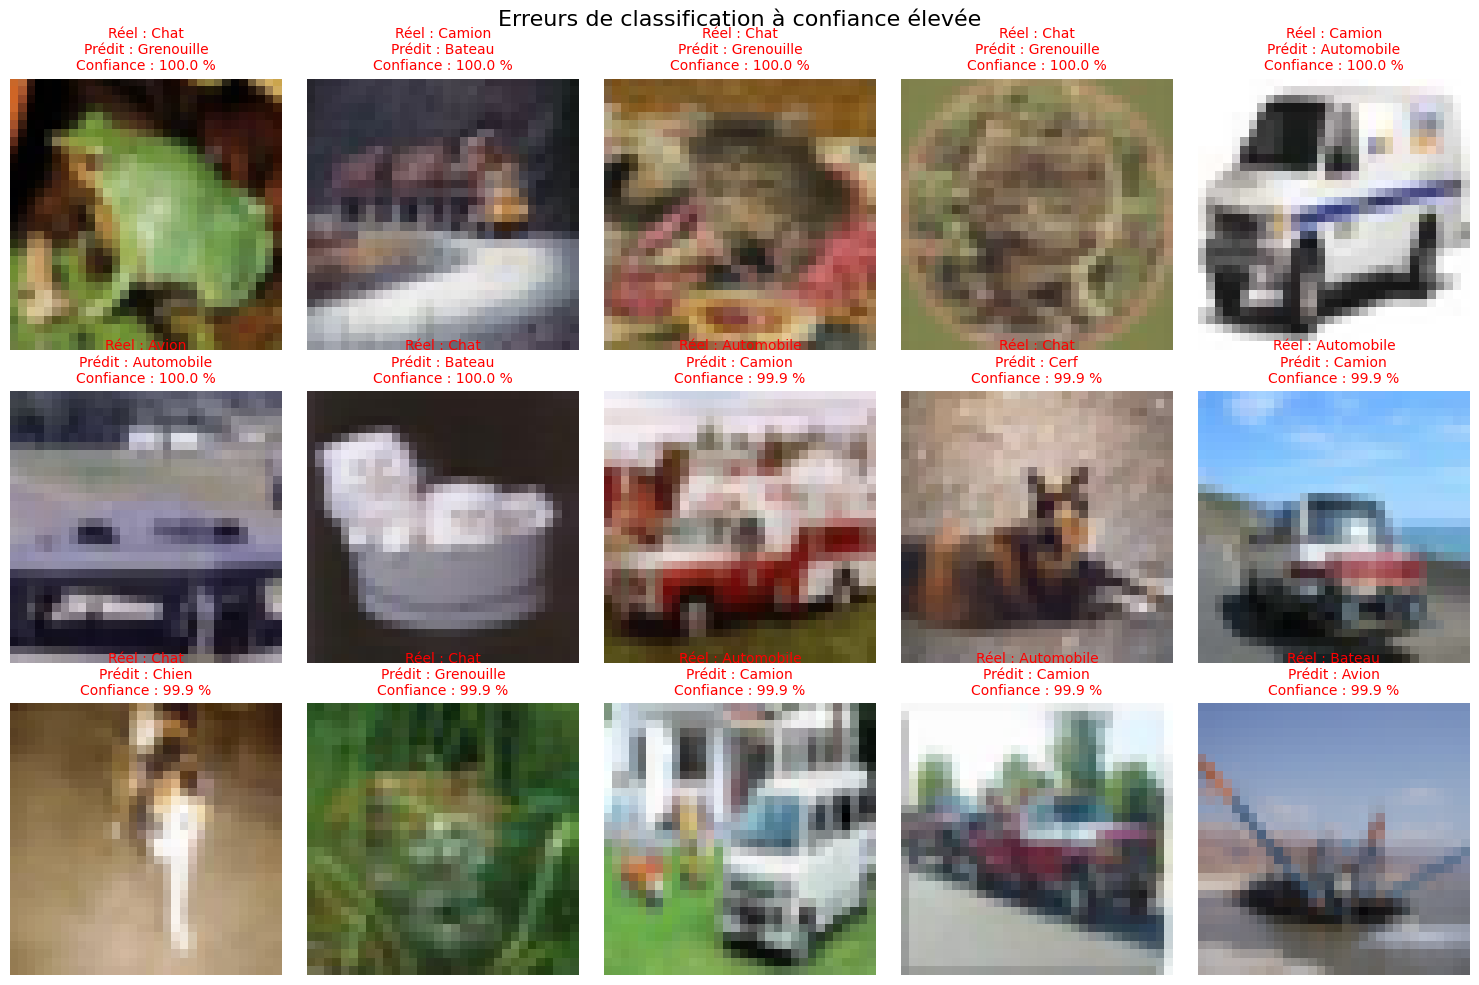

In [25]:
# Probabilités prédites
y_prob_v2 = model_v2.predict(
    X_test_norm,
    verbose=0
)

confidence = np.max(y_prob_v2, axis=1)

plt.figure(figsize=(15, 10))

# Sélection des 15 erreurs les plus confiantes
sorted_errors = wrong_indices[
    np.argsort(confidence[wrong_indices])[::-1]
][:15]

for i, idx in enumerate(sorted_errors):

    plt.subplot(3, 5, i + 1)

    plt.imshow(X_test[idx])

    plt.title(
        f"Réel : {class_names[y_test[idx]]}\n"
        f"Prédit : {class_names[y_pred_v2[idx]]}\n"
        f"Confiance : {confidence[idx]*100:.1f} %",
        color="red",
        fontsize=10
    )

    plt.axis("off")

plt.suptitle(
    "Erreurs de classification à confiance élevée",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "erreurs_confiance_V2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()